In [ ]:
import os
import json
import numpy as np
import pandas as pd
from datetime import datetime
from pathlib import Path
from matplotlib import pyplot as plt
import h5py
import subprocess
from snudda.utils.load import SnuddaLoad
from snudda import Snudda
from snudda.input import SnuddaInput

class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        return json.JSONEncoder.default(self, obj)

def update_param_values(data, search_term="gbar_k", new_value=0):
    if isinstance(data, dict):
        if "param_name" in data and isinstance(data["param_name"], str):
            if search_term in data["param_name"]:
                print(f"  -> Updating {data['param_name']} to {new_value}")
                data["value"] = new_value
        for key, value in data.items():
            update_param_values(value, search_term, new_value)
    elif isinstance(data, list):
        for item in data:
            update_param_values(item, search_term, new_value)

def modify_json_file(input_path):
    try:
        # 1. Load data first
        with open(input_path, 'r') as f:
            content = json.load(f)
        
        # 2. Modify content
        update_param_values(content)

        # 3. Rename original to _old
        directory = os.path.dirname(input_path)
        old_path = os.path.join(directory, "parameters_old.json")
        
        # Guard against renaming if 'parameters_old.json' already exists
        if os.path.exists(old_path):
            os.remove(old_path) 
            
        os.rename(input_path, old_path)
        
        # 4. Save new data to the ORIGINAL filename
        with open(input_path, 'w') as f:
            json.dump(content, f, indent=4)
            
        print(f"Successfully updated: {input_path}")
        
    except FileNotFoundError:
        print(f"Error: {input_path} not found.")
    except Exception as e:
        print(f"An error occurred: {e}")

def update_nmda_ratio(syn_config, ratio):
    with open(syn_config, "r") as f:
        config = json.load(f)
    config["1"]["synapse"]["nmda_ratio"] = ratio

    with open(syn_config, "w") as f:
        json.dump(config, f, indent=4)

def run_nmda_VC(snudda_data_path, rds, ratio,
                nmda_config, hold_v, flag, simulation_time, act_time, number_neurons, neuron_path, num_inputs, g_nmda):

    if act_time + 0.2 >= simulation_time:
        raise ValueError("Simulation must continue at least 200 ms after stimulation.")

    neuron_name = os.path.basename(neuron_path)
    update_nmda_ratio(nmda_config, ratio)
    network_path = os.path.join(os.getcwd(), "network", f"test_{flag}_{ratio}_{neuron_name}_{num_inputs}_nmdafixed{g_nmda}")
    ss = Snudda(network_path=str(network_path))
    
    ss.init_tiny(
            neuron_paths=[str(neuron_path)],
            snudda_data=snudda_data_path,
            neuron_names=["dSPN"],
            number_of_neurons=[number_neurons],
            random_seed=rds
        )

    ss.create_network()

    sl = SnuddaLoad(os.path.join(network_path, "network-neuron-positions.hdf5"))
    neurons = sl.data["neurons"]
    neuron_ids = [int(n["neuron_id"]) for n in neurons]

    csv_path = os.path.join(network_path, "input.csv")
    base_seq = act_time
    data = np.tile(base_seq, (num_inputs, 1))
    pd.DataFrame(data).to_csv(csv_path, index=False, header=False)

    g_ampa = g_nmda/ratio
    config = {
        "generator": "csv",
        "csv_file": csv_path,
        "type": "AMPA_NMDA",
        "conductance": g_ampa,
        "mod_file": "tmGlut",
        "synapse_density": "1.15*0.05/(1+exp(-(d-30e-6)/5e-6))",
        "parameter_file": nmda_config,
        "num_inputs": num_inputs,
    }

    input_file = os.path.join(network_path, "input.json")
    input_data = {str(nid): {"cortical_act": config} for nid in neuron_ids}

    with open(input_file, "w", encoding="utf-8") as f:
        json.dump(input_data, f, indent=4)

    SnuddaInput(
        network_path=network_path,
        snudda_data=snudda_data_path,
        use_meta_input=False,
        input_config_file=input_file,
        verbose=False,
        random_seed=rds,
        time=simulation_time,
    ).generate()

    spike_data_path = os.path.join(network_path, "input-spikes.hdf5")

    sim_config = {
        "network_path": network_path,
        "time": simulation_time,
        "input_file": spike_data_path
    }

    volt_clamp_info = {}
    for p in neuron_ids:
        volt_clamp_info[str(p)] = {
            "voltage": hold_v,
            "duration": simulation_time,
            "save_current": True
        }

    sim_config["voltage_clamp"] = volt_clamp_info

    simulation_config_file = os.path.join(network_path, "simulation-config.json")
    print(f"Writing simulation config: {simulation_config_file}")

    with open(simulation_config_file, "w") as f:
        json.dump(sim_config, f, indent=4, cls=NumpyEncoder)

    cmd = [
        "mpirun", "-n", "6", "snudda", "simulate",
        network_path, "--simulation_config", simulation_config_file
    ]

    print(" ".join(cmd))
    subprocess.run(cmd, check=True)

    return network_path


def collect_amp_data(network_path, flag, t_stimulate, output_path,neuron_path, ratio, num_inputs, show_plot=False):
    sl = SnuddaLoad(os.path.join(network_path, "network-neuron-positions.hdf5"))
    neurons = sl.data["neurons"]
    neuron_ids = [int(n["neuron_id"]) for n in neurons]
    fpath = os.path.join(network_path, "simulation", "output.hdf5")
    neuron_name = os.path.basename(neuron_path)
    output_fig_path = os.path.join(output_path, f"PSC_{flag}_{neuron_name}_{ratio}_{num_inputs}.jpg")

    dt = 0.025
    t_stimulate = t_stimulate * 1000  # Convert to ms

    # Baseline before stimulation
    t_s_base_ms, t_e_base_ms = t_stimulate - 100, t_stimulate - 20

    # Plotting window
    t_s_ms, t_e_ms = t_stimulate - 25, t_stimulate + 300

    t_s_base, t_e_base = int(t_s_base_ms / dt), int(t_e_base_ms / dt)
    t_s, t_e = int(t_s_ms / dt), int(t_e_ms / dt)

    # AMPA peak window
    t_ampa_s = int(t_stimulate / dt)
    t_ampa_e = int((t_stimulate + 20) / dt)

    # NMDA window: 50–60 ms after stimulation
    window_index_s = int((t_stimulate + 50) / dt)
    window_index_e = int((t_stimulate + 60) / dt)

    amp_list = {}
    preserve_id = []
    with h5py.File(fpath, "r") as f:
        for p in neuron_ids:
            epsc = f["neurons"][str(p)]["current"][0] * 1e12
            baseline = np.mean(epsc[t_s_base:t_e_base])
            epsc_subtract = epsc - baseline

            if flag == "ampa":
                amp = abs(np.min(epsc_subtract[t_ampa_s:t_ampa_e]))
            elif flag == "nmda":
                amp = np.mean(epsc_subtract[window_index_s:window_index_e])
            else:
                raise ValueError("flag must be 'ampa' or 'nmda'")
            if amp>=0:
                amp_list[p] = amp
                preserve_id.append(p)

            if show_plot:
                time = np.arange(len(epsc)) * dt
                print(f"Plotting PSC for post-synaptic neuron {p}")
                plt.plot(time[t_s:t_e], epsc_subtract[t_s:t_e], c='k')
                if p not in preserve_id:
                    plt.plot(time[t_s:t_e], epsc_subtract[t_s:t_e], c='orange')

    if show_plot:
        plt.axvline(t_stimulate, color="red", linestyle="--", label="Stimulus")

        if flag == "nmda":
            plt.axvspan(t_stimulate + 50, t_stimulate + 60,
                        color="orange", alpha=0.2, label="NMDA window")

        plt.xlabel("Time (ms)")
        plt.ylabel("PSC (pA)")
        plt.legend()
        plt.grid()
        plt.savefig(output_fig_path, dpi=300)
        plt.show()

    return amp_list,preserve_id

In [ ]:
# example for ispn, have to switch the neuron folder and syn_condig file of dspn
# the nmda_config file is just one copy if the synaptic parmameters so that we dont directly edit BG data synaptic parameter json file
snudda_data_path = (
    "/Users/peirui/code_collection/BasalGangliaData/data"
)
rds = 123
ratio_list = [0.1,1,2,3,4,5]
nmda_config = "/Users/peirui/code_collection/treem/tutorials/syn_distribution/syn_config/msnd2-m1rh-ipsi.json"
v_hold_ampa = -81e-3 # -11mv liquid junction potential
v_hold_nmda = 29e-3 # -11mv liquid junction potential
simulation_time_nmda = 5
act_time_nmda = 4
simulation_time_ampa = 2
act_time_ampa = 1
num_inputs = 10
number_neurons = 8
g_nmda = 5e-10
output_path = "/Users/peirui/code_collection/treem/tutorials/syn_distribution/output_syn_distribution_gampa/"
Path(output_path).mkdir(parents=True, exist_ok=True)
neuron_folder="/Users/peirui/code_collection/BasalGangliaData/data/neurons/striatum/ispn/nmda_ratio_VC"
result_final={}
for name in os.listdir(neuron_folder):
    if name.startswith("str"):
        neuron_path = os.path.join(neuron_folder, name)
        modify_json_file(os.path.join(neuron_path,"parameters.json"))
        result={}
        for ratio in ratio_list:
            network_path_ampa = run_nmda_VC(snudda_data_path,rds,ratio,nmda_config,v_hold_ampa,"ampa",simulation_time_ampa,act_time_ampa,number_neurons, neuron_path, num_inputs,g_nmda)
            network_path_nmda = run_nmda_VC(snudda_data_path, rds,ratio,nmda_config,v_hold_nmda,"nmda",simulation_time_nmda,act_time_nmda,number_neurons, neuron_path, num_inputs,g_nmda)

            amp_list_ampa,preserve_id_ampa = collect_amp_data(network_path_ampa,"ampa",act_time_ampa,output_path,neuron_path,ratio, num_inputs,show_plot=False)
            amp_list_nmda, preserve_id_nmda = collect_amp_data(network_path_nmda,"nmda",act_time_nmda,output_path, neuron_path, ratio, num_inputs,show_plot=False)
            nmda_ampa_ratio = [amp_list_nmda[p] / amp_list_ampa[p] for p in preserve_id_nmda]
            result[ratio] = [nmda_ampa_ratio,amp_list_ampa,amp_list_nmda]
            print(f"NMDA/AMPA ratio for {len(nmda_ampa_ratio)} neurons: {np.mean(nmda_ampa_ratio)} ± {np.std(nmda_ampa_ratio)}")
        result_final[name] = result
with open(os.path.join(output_path, f"nmda_ampa_ratio_{ratio_list}_summary_ispn_syn10_numneuron8.json"), "w") as f:
    json.dump(result_final, f, indent=4)

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter


# =====================================================================
# Configuration & Constants
# =====================================================================

BASE_COLORS = {
    "dSPN": "#006AA7",  # Blue
    "iSPN": "#C0392B",  # Red
    "other": "#4E8975",
}

REF_GREY = "#333333"
REFERENCE_LINES = [
    (0.24, "S1", REF_GREY, 0.35),
    (0.32, "M1", REF_GREY, 0.60),
    (1.12, "PF", REF_GREY, 0.90),
]

COLS_INFO = [
    (0, 0, "Measured current-based NMDA/AMPA ratio", "NMDA/AMPA ratio"),
    (1, 1, "AMPA amplitude (pA)", "AMPA amplitude"),
]

LOG_XTICKS = [0.1, 1, 2, 3, 4, 5]


# =====================================================================
# Data & Style Helpers
# =====================================================================

def extract_numeric_array(val):
    """Safely convert dicts, scalar values, or lists into a flat 1D numpy array of floats."""
    if isinstance(val, dict):
        return np.array(
            [v for v in val.values() if isinstance(v, (int, float, np.number))],
            dtype=float,
        )
    if isinstance(val, (list, tuple, np.ndarray)):
        flat = []
        for item in val:
            if isinstance(item, (int, float, np.number)):
                flat.append(float(item))
            elif isinstance(item, dict):
                num = next(
                    (v for v in item.values() if isinstance(v, (int, float, np.number))),
                    None,
                )
                if num is not None:
                    flat.append(float(num))
        return np.array(flat, dtype=float)
    if isinstance(val, (int, float, np.number)):
        return np.array([float(val)], dtype=float)
    return np.array([], dtype=float)


def parse_neuron_type(neuron_full_name):
    """Extract 'dSPN', 'iSPN', or 'other' from a full neuron identifier."""
    parts = neuron_full_name.replace("str-", "").split("-")
    for part in parts:
        if part.lower() == "dspn":
            return "dSPN"
        if part.lower() == "ispn":
            return "iSPN"
    return "other"


def build_neuron_styles(neuron_names):
    """Compute per-neuron colors and progressive alpha levels grouped by subtype."""
    parsed_types = [parse_neuron_type(name) for name in neuron_names]
    type_totals = {k: parsed_types.count(k) for k in BASE_COLORS}
    type_counters = {k: 0 for k in BASE_COLORS}

    styles = []
    for ntype in parsed_types:
        type_counters[ntype] += 1
        idx = type_counters[ntype]
        total = type_totals[ntype]

        line_alpha = 0.50 + 0.50 * (idx - 1) / (total - 1) if total > 1 else 0.95
        scatter_alpha = 0.05 + 0.05 * (idx - 1) / max(1, total - 1)

        styles.append({
            "type": ntype,
            "color": BASE_COLORS[ntype],
            "linestyle": "-",
            "line_alpha": line_alpha,
            "scatter_alpha": scatter_alpha,
        })
    return styles


# =====================================================================
# Axis & Plot Helpers
# =====================================================================

def setup_figure_grid(layout, show_log_row):
    """Initialize matplotlib rcParams and figure subplots for the requested layout."""
    plt.rcParams.update({
        "font.size": 16,
        "axes.titlesize": 20,
        "axes.labelsize": 18,
        "xtick.labelsize": 15,
        "ytick.labelsize": 15,
        "legend.fontsize": 16,
        "legend.title_fontsize": 17,
    })

    if layout not in ("2x2", "1x4"):
        raise ValueError("layout must be '2x2' or '1x4'")

    if not show_log_row:
        n_rows, n_cols, figsize = 1, 2, (17, 7.5)
    elif layout == "2x2":
        n_rows, n_cols, figsize = 2, 2, (17, 15)
    else:
        n_rows, n_cols, figsize = 1, 4, (32, 7.5)

    return plt.subplots(n_rows, n_cols, figsize=figsize, squeeze=False)


def add_g_ampa_top_axis(
    ax,
    tick_ratios,
    g_nmda_ns,
    is_log=False,
    show_title=True,
    title_text="AMPA Amplitude",
    xlabel_fontsize=16,
    xtick_fontsize=15,
    title_pad=38,
):
    """Attach a secondary top x-axis showing AMPA conductance g_AMPA = g_NMDA / Ratio."""
    ax_top = ax.twiny()
    if is_log:
        ax_top.set_xscale("log")
        ax_top.minorticks_off()
    ax_top.set_xlim(ax.get_xlim())
    ax_top.set_xticks(tick_ratios)

    g_ampa_labels = [
        f"{g_nmda_ns / r:.2f}".rstrip("0").rstrip(".") if r != 0 else "∞"
        for r in tick_ratios
    ]
    ax_top.set_xticklabels(g_ampa_labels, fontsize=xtick_fontsize, color="#4A4A4A")
    ax_top.set_xlabel(
        f"AMPA Conductance $g_{{AMPA}}$ (nS) [for fixed $g_{{NMDA}} = {g_nmda_ns}$ nS]",
        fontsize=xlabel_fontsize,
        color="#4A4A4A",
        labelpad=8,
    )
    ax_top.spines["right"].set_visible(False)
    if show_title:
        ax_top.set_title(title_text, fontsize=20, fontweight="bold", pad=title_pad)


def format_panel_axes(ax, metric_idx, ylabel, panel_title, is_log, active_xticks):
    """Apply consistent ticks, log scaling, spines, and labels to a subplot."""
    if is_log:
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.xaxis.set_major_formatter(ScalarFormatter())
        ax.ticklabel_format(axis="x", style="plain")
        ax.minorticks_off()
        title_str = f"{panel_title} (log-log)"
    else:
        title_str = panel_title

    ax.set_xlabel("Conductance-based NMDA/AMPA ratio", fontsize=18, labelpad=8)
    ax.set_ylabel(ylabel, fontsize=18, labelpad=8)
    if metric_idx != 1:
        ax.set_title(title_str, fontsize=20, fontweight="bold", pad=16)

    ax.set_xticks(active_xticks)
    ax.set_xticklabels([f"{r:g}" for r in active_xticks], fontsize=15)
    ax.tick_params(axis="y", labelsize=15)

    ax.spines["right"].set_visible(False)
    if metric_idx != 1:
        ax.spines["top"].set_visible(False)


def add_reference_lines(ax, max_x):
    """Draw horizontal reference lines and right-margin labels on the ratio panel."""
    for y_val, text, col, ref_alpha in REFERENCE_LINES:
        ax.axhline(y=y_val, color=col, linestyle=":", linewidth=1.4, alpha=ref_alpha)
        ax.text(
            x=max_x * 1.03,
            y=y_val,
            s=text,
            color=col,
            alpha=ref_alpha,
            fontsize=14,
            fontweight="semibold",
            ha="left",
            va="center",
            clip_on=False,
        )


# =====================================================================
# Main Plotting Function
# =====================================================================

def plot_neuron_ratios(
    json_data,
    mode,
    output_path,
    g_nmda_ns=0.5,
    show_log_row=True,
    show_ref_lines=True,
    layout="2x2",
    log_top_xlabel_fontsize=12,
    log_top_xtick_fontsize=11,
):
    if not json_data:
        raise ValueError("json_data cannot be empty.")

    fig, axes = setup_figure_grid(layout, show_log_row)
    neuron_styles = build_neuron_styles(json_data.keys())

    sample_neuron = next(iter(json_data.values()))
    ratio_items = sorted([(float(k), k) for k in sample_neuron.keys()], key=lambda x: x[0])
    target_ratios = [x[0] for x in ratio_items]

    num_scales = 2 if show_log_row else 1

    for scale_idx in range(num_scales):
        is_log = scale_idx == 1

        def get_ax(metric_idx):
            if layout == "1x4" and show_log_row:
                return axes[0, scale_idx * 2 + metric_idx]
            return axes[scale_idx, metric_idx]

        linear_jitter = (
            (target_ratios[1] - target_ratios[0]) * 0.05
            if len(target_ratios) > 1
            else 0.05
        )

        # Plot scatter points and mean curves per neuron
        for (neuron_full_name, neuron_data), style in zip(json_data.items(), neuron_styles):
            for metric_idx, data_idx, _, _ in COLS_INFO:
                ax = get_ax(metric_idx)
                means = []

                for ratio_num, ratio_key in ratio_items:
                    if ratio_key not in neuron_data:
                        means.append(np.nan)
                        continue

                    vals = extract_numeric_array(neuron_data[ratio_key][data_idx])
                    if is_log:
                        vals = vals[vals > 0]

                    if len(vals) == 0:
                        means.append(np.nan)
                        continue

                    means.append(np.mean(vals))

                    rng = np.random.default_rng(
                        int(round(ratio_num * 100)) + abs(hash(neuron_full_name)) % 10000
                    )
                    if is_log:
                        x_pos = ratio_num * (10 ** rng.uniform(-0.025, 0.025, size=len(vals)))
                    else:
                        x_pos = ratio_num + rng.uniform(-linear_jitter, linear_jitter, size=len(vals)) * 2

                    ax.scatter(
                        x_pos,
                        vals,
                        color=style["color"],
                        alpha=style["scatter_alpha"],
                        s=32,
                        edgecolors="none",
                    )

                valid_ratios = [r for r in target_ratios if not is_log or r > 0]
                valid_means = [
                    m for r, m in zip(target_ratios, means) if not is_log or r > 0
                ]
                ax.plot(
                    valid_ratios,
                    np.array(valid_means, dtype=float),
                    linestyle=style["linestyle"],
                    linewidth=2.4,
                    color=style["color"],
                    alpha=style["line_alpha"],
                )

        # Use filtered log ticks on log panels and actual ratios on linear panels
        active_xticks = (
            [r for r in LOG_XTICKS if min(target_ratios) <= r <= max(target_ratios)]
            if is_log
            else target_ratios
        ) or target_ratios

        for metric_idx, _, ylabel, panel_title in COLS_INFO:
            format_panel_axes(
                get_ax(metric_idx), metric_idx, ylabel, panel_title, is_log, active_xticks
            )

        add_g_ampa_top_axis(
            get_ax(1),
            active_xticks,
            g_nmda_ns,
            is_log=is_log,
            show_title=True,
            title_text="AMPA amplitude (log-log)" if is_log else "AMPA amplitude",
            xlabel_fontsize=log_top_xlabel_fontsize if is_log else 16,
            xtick_fontsize=log_top_xtick_fontsize if is_log else 15,
            title_pad=18,
        )

        if show_ref_lines:
            add_reference_lines(get_ax(0), max(target_ratios))

    # Legend matching BASE_COLORS keys
    legend_handles = [
        Line2D([0], [0], color=BASE_COLORS["dSPN"], lw=2.4, label="dSPN"),
        Line2D([0], [0], color=BASE_COLORS["iSPN"], lw=2.4, label="iSPN"),
    ]
    axes[0, -1].legend(
        handles=legend_handles,
        title="",
        frameon=False,
        bbox_to_anchor=(1.04, 1),
        loc="upper left",
        fontsize=16,
        title_fontsize=17,
    )

    # fig.suptitle(
    #     f"NMDA/AMPA ratio using {mode} method, num_inputs=10, num_neuron=60, g_nmda fixed at {g_nmda_ns}nS (K+ blocked)",
    #     fontsize=22,
    #     fontweight="bold",
    #     y=1.02,
    # )
    plt.tight_layout(rect=[0, 0, 0.93, 0.97])

    os.makedirs(output_path, exist_ok=True)
    log_suffix = f"_with_log_{layout}" if show_log_row else ""
    ref_suffix = "" if show_ref_lines else "_noref"
    save_path = os.path.join(
        output_path, f"nmda_ampa_summary_{mode}{log_suffix}{ref_suffix}_30syn.png"
    )
    fig.savefig(save_path, dpi=500, bbox_inches="tight")
    plt.show(fig)
    return fig, axes

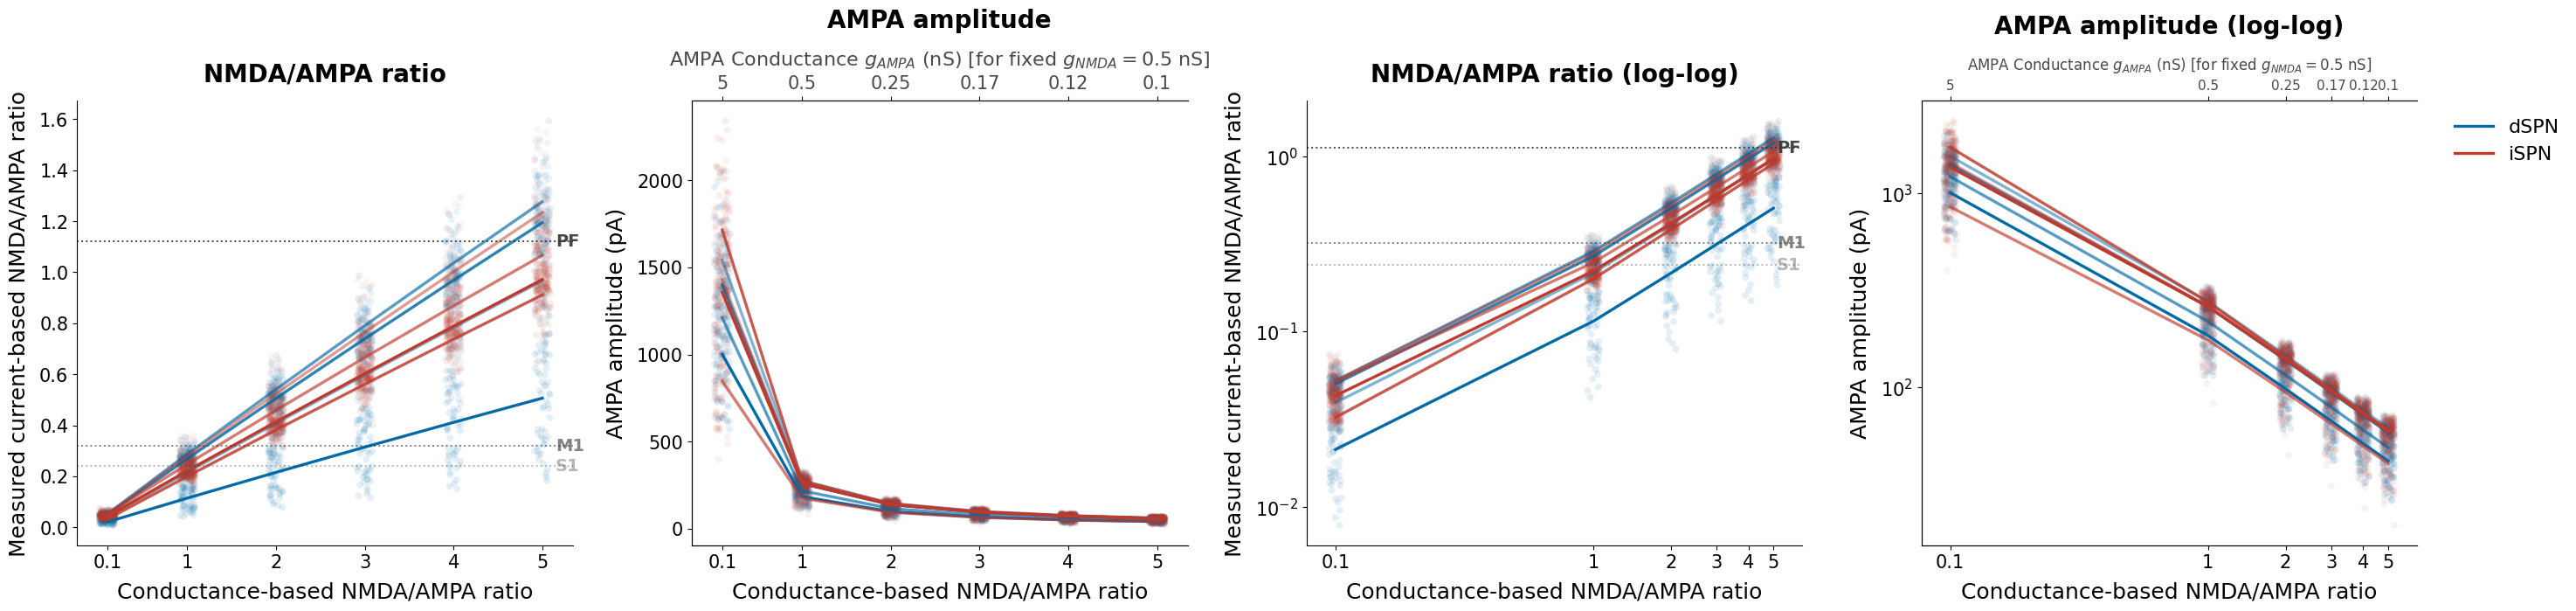

(<Figure size 3200x750 with 6 Axes>,
 array([[<Axes: title={'center': 'NMDA/AMPA ratio'}, xlabel='Conductance-based NMDA/AMPA ratio', ylabel='Measured current-based NMDA/AMPA ratio'>,
         <Axes: xlabel='Conductance-based NMDA/AMPA ratio', ylabel='AMPA amplitude (pA)'>,
         <Axes: title={'center': 'NMDA/AMPA ratio (log-log)'}, xlabel='Conductance-based NMDA/AMPA ratio', ylabel='Measured current-based NMDA/AMPA ratio'>,
         <Axes: xlabel='Conductance-based NMDA/AMPA ratio', ylabel='AMPA amplitude (pA)'>]],
       dtype=object))

In [133]:
output_path = "/Users/peirui/OneDrive - Karolinska Institutet/Sim/network_nmda_ratio_scan_result"
output_json_path_dspn = os.path.join(output_path, "nmda_ampa_ratio_[0.1, 1, 2, 3, 4, 5]_summary_dspn_syn10_numneuron60.json")
output_json_path_ispn = os.path.join(output_path, "nmda_ampa_ratio_[0.1, 1, 2, 3, 4, 5]_summary_ispn_syn10_numneuron60.json")

with open(output_json_path_dspn, "r") as f1, open(output_json_path_ispn, "r") as f2:
    data1 = json.load(f1)
    data2 = json.load(f2)
   
merged_data = data1 | data2


plot_neuron_ratios(
    merged_data,
    mode="gnmda_fixed",
    output_path=output_path,
    g_nmda_ns=0.5,
    show_log_row=True,
    show_ref_lines=True,
    layout="1x4"
)